## Getting Data from an API - The Met Museum (REST API)


This notebook is designed to work in a stepwise manner to build an understanding for programmatically making an API request, the various considerations and possibilities. This is a pre-prepared workbook, and follows some stepwise options and examples for demonstrative purposes. With an increased familiarity with your own domain, ways of working, and goals, it aims to show a variety of steps a user can take but is not an exhaustive programme.

The notebook is split into 3 sections and we will work through in a stepwise manner. The images for the API use in the notebook are from the Met Museum documentation.

> Important notes about this notebook
- Talks to a live external API (The Met),
- And then fetches live external images (another host/CDN),
- Environment/IP differences for images (Noteable vs home machine vs Colab vs Kaggle, etc. → 403 variability).

**Search 1**

Installations

In [ ]:
%pip install requests pandas matplotlib wordcloud

In [2]:
# These are some of the required imports for the session
import requests              # For sending HTTP requests to the API
import json                  # For working with JSON responses
from pathlib import Path     # For file/directory path handling
import pandas as pd          # For working with tabular data
import pprint                # For readable display of nested JSON objects and other printed items
import time                  # Adding time delay when we get data from the API
from collections import Counter #counting things
import matplotlib.pyplot as plt #making a visualisation
from wordcloud import WordCloud


----------------------------------------------SECTION 1--------------------------------------------------

Now that important features and libraries are imported and we have them ready, we can start a request process with the Met Museum API. Starting simple and adding new elements as we work though the code book.


**What is this code block doing?**

1. **Base URL:**

   `https://collectionapi.metmuseum.org/public/collection/` is the common root address for the Met Collection API.

2. **Endpoint `/v1.1/search`:**

   This is used to find object IDs based on keywords. The URL becomes:

   [https://collectionapi.metmuseum.org/public/collection/v1.1/search](https://collectionapi.metmuseum.org/public/collection/v1.1/search)

   - Note the addition of **`v1.1/search`** in the URL. The `v1.1` indicates the updated version of the search endpoint. Other endpoints, such as those used to retrieve individual objects, still use `v1`.

3. **Query parameters:**

   The query parameter **`q`** is used in the code block to specify our search term.

   Additionally, **`hasImages`** was included to return objects that have associated images. Removing this parameter allows the search to include objects without images.

   - **Note:** During earlier exploration, removing this parameter returned 96 results. This is interesting and worth investigating. However, differences in result counts do not necessarily indicate that records with images have fuller metadata. Search behaviour, filtering and API versions can also influence results. This highlights why researchers should examine their search parameters carefully.

   The updated search endpoint also introduces two parameters:

   - **`offset`** determines where in the results we begin retrieving object IDs. An offset of `0` starts at the first result.
   - **`limit`** determines how many object IDs are returned in one request. We have chosen `10` for this example.

   This is called **pagination**. The API may find many matching objects, but we retrieve only a portion of them at a time.

4. **Check the status code:**

   We check whether the API request was successful. For example, `200` indicates success, while `404` indicates that a requested resource was not found.

5. **Inspect the response:**

   We inspect what we have retrieved and print some details before proceeding.

   The `total` value tells us how many objects match the search overall, while `objectIDs` contains the IDs returned for the requested page.

   We also print the full request URL so we can see how Python has combined our endpoint and query parameters.

All the sentences in green beginning with a **`#`** are annotations we have added to explain the code and what is being executed. These are called **comments** in Python and are not executed as code.


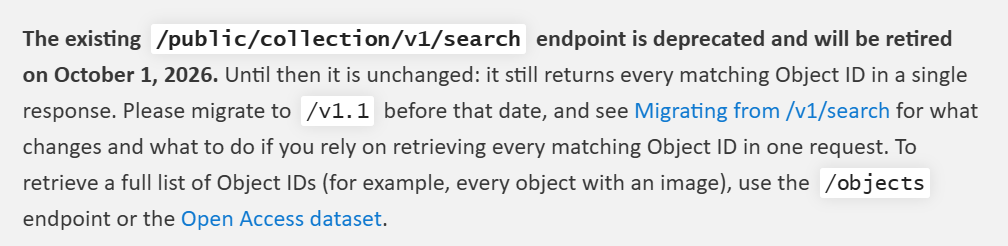

A previous iteration of this code was working with v1 of the API endpoint, checking the documentation is important. New updates help us to best send the requests to the updated version. The updated endpoint introduces **pagination**, allowing us to retrieve a specified number of results at a time using the `offset` and `limit` parameters.

In [7]:

# Define the search term - lets say we want to search items related to this term
search_term = "sunflowers" #### search term is defined by us, you can call it anything, keyword, search or other, it is set out here so we can use it later without verbose labels.
#We use it below in the query parameters 'q' and our term 'sunflowers' is saved in there. We chose to use search_terms since it is easy to understand.

# Define the MET API endpoint and search parameters
# The MET now uses v1.1 for searches, which returns results in pages.
search_url = "https://collectionapi.metmuseum.org/public/collection/v1.1/search"

params = {
    "q": search_term, # 'q' is the query parameter used by the MET API documentation for keyword searches
    "hasImages": "true", # Only return objects that have associated images, can remove this if not of interest.
    "offset": 0, # Start at the first result (Python starts counting from 0).
    "limit": 10 # Only return 10 object IDs in this request. This can be changed.
}

# The API may find many matching objects, but returns only the requested page.
# 'total' tells us how many matches exist overall, while 'limit' controls how many IDs we retrieve.

# Send a GET request to the MET API - this will get the object IDs from our search and we can save those
response = requests.get(search_url, params=params, timeout=20)
# NEW: timeout=20 means Python will not keep waiting indefinitely if the API stops responding.

#Check HTTP response status code
# Most REST APIs return a status code:
# 200 = OK, 400+ = error, e.g. 404 = not found
print("Status code:", response.status_code)

# Display the complete URL generated using our parameters.
print("Request URL:", response.url)

# Stop the code if the API returns an unsuccessful HTTP status.
response.raise_for_status()

# Convert the response to JSON format (Python dictionary)
search_data_1 = response.json() #Now we have the json converted to a dictionary to examine, we call in search_data_1 to keep it identifiable for this stage. Note: We haven't save it, just inspecting and using to build our query up.
#MET API returns a list of matching objectIDs in the response JSON, objectID is a documented feature of the MET API, we will inspect this in the later steps.

## A BREAKDOWN OF OUTPUTS FROM OUR STEPS SO FAR--->

#This response is a simple search output that we got back as a JSON, it contains two items here, the total and the object ID. We can now use this information for our further queries.
print(search_data_1.keys())

# Preview how many items were found by the API
print("Total results found:", search_data_1.get("total"))

# Display the object IDs returned for this page of the search
print("Object IDs returned:", search_data_1.get("objectIDs") or [])




Status code: 200
Request URL: https://collectionapi.metmuseum.org/public/collection/v1.1/search?q=sunflowers&hasImages=true&offset=0&limit=10
dict_keys(['total', 'objectIDs'])
Total results found: 153
Object IDs returned: [436524, 480725, 484935, 437112, 210191, 486590, 822589, 375281, 705155, 262423]


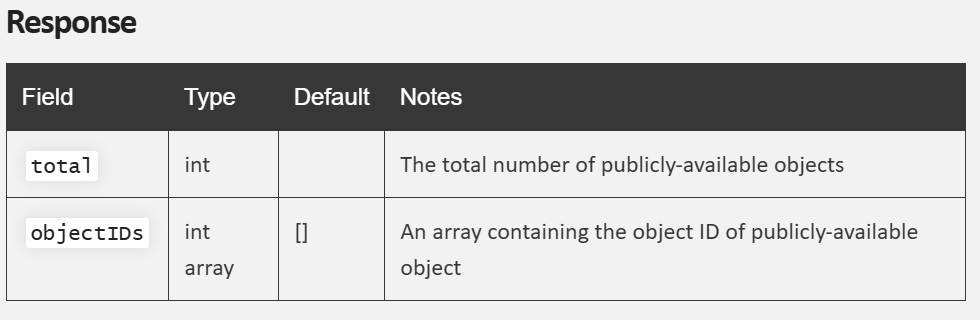

The output view shows the layers of information we have from the simple search so far. 

We sent a search request to the MET Collection API using the `requests` library.

- We specify a keyword in **search_term** (`sunflowers`).
- The API returns a list of object IDs that match our query.
- We checked the status code and it was 200 which means the search was successful.
- We'll use the IDs to get the metadata in the next step.

In [8]:

# Save the search JSON - search_1 - so that we have it for traceability.

# Where do we save it--->
metadata_dir = Path("Metadata")

#This is based on the file structure used in this repository where we save outputs in different folders outside of the notebooks folder.

# Save the initial search JSON
search_output_path = metadata_dir / "sunflowers_search_data_1.json"
with open(search_output_path, "w", encoding="utf-8") as f:
    json.dump(search_data_1, f, indent=2)

#This initial search is saved with the suffix **search data 1** assigned by us for tracing.


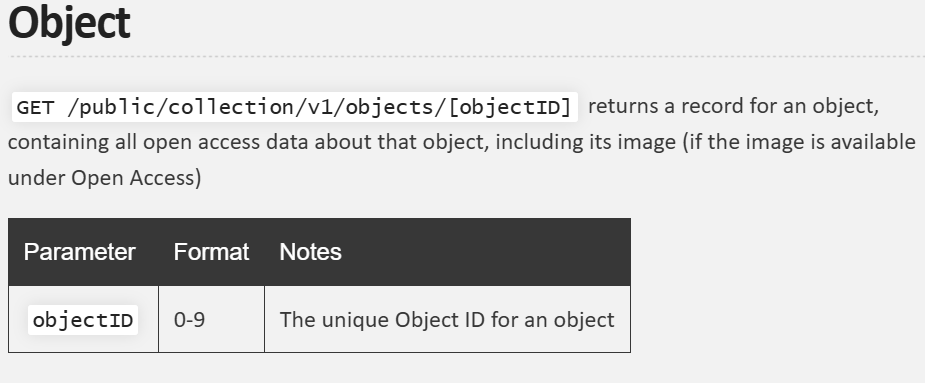

**Retrieving an individual object's metadata**

Our initial search returned a list of object IDs. We can now use one of these IDs to retrieve the full metadata associated with that object.

The Met uses the following endpoint:

`https://collectionapi.metmuseum.org/public/collection/v1/objects/{objectID}`

Here, `{objectID}` is replaced with the unique numerical identifier of the object we want to examine.

**Note:** Although the search endpoint has been updated to `/v1.1/search`, the endpoint for retrieving individual objects still uses `/v1/objects/`.

The API returns a JSON record containing information such as the object's title, artist, date, department and available images.

Now we have the object IDs matching for the item we searched, we can setup a URL to get the associated metadata for specified object. Starting with just one object to demonstrate the steps:

We can now make the request to get the full metadata for this object and print out some of the included metadata to see whats there:
When setting up inputs and outputs, the naming convention we use is wordy but helps for clarity, for example specifying search_1 and so forth. This helps whilst we are working in the 
same notebook and keeping some clarity in our outputs.

- Inspecting the metadata JSON for a single object

In [ ]:

# Get the first Object ID from the search results
first_example_id = search_data_1.get("objectIDs", [])[0] #we take the first ID from the list we obtained earlier, in python this would start at point 0 for the FIRST item.

# Display the selected ID so we know which object we are examining
print("Selected Object ID:", first_example_id)


# Build the URL to get full metadata for this object
object_url_search1 = f"https://collectionapi.metmuseum.org/public/collection/v1/objects/{first_example_id}"

# Send a GET request to retrieve the object's metadata
object_response_search1 = requests.get(object_url_search1, timeout=20)

#Check HTTP response status code
# Most REST APIs return a status code:
# 200 = OK, 400+ = error, e.g. 404 = not found
print("Status code:", object_response_search1.status_code)

# Stop if the API request was unsuccessful
object_response_search1.raise_for_status()

# Convert the JSON response into a Python dictionary
object_data_search1 = object_response_search1.json()

#Let's see which fields are available - Preview the full metadata structure
pprint.pprint(object_data_search1) #Pretty print the full metadata so we can explore available fields

# the output below is scrollable, and you can see all the available metadata for the one item (ID printed above).


Scrolling down in the output will show that the first object ID was 436524 and a number of features of metadata are available for that object. It is from Van Gogh 

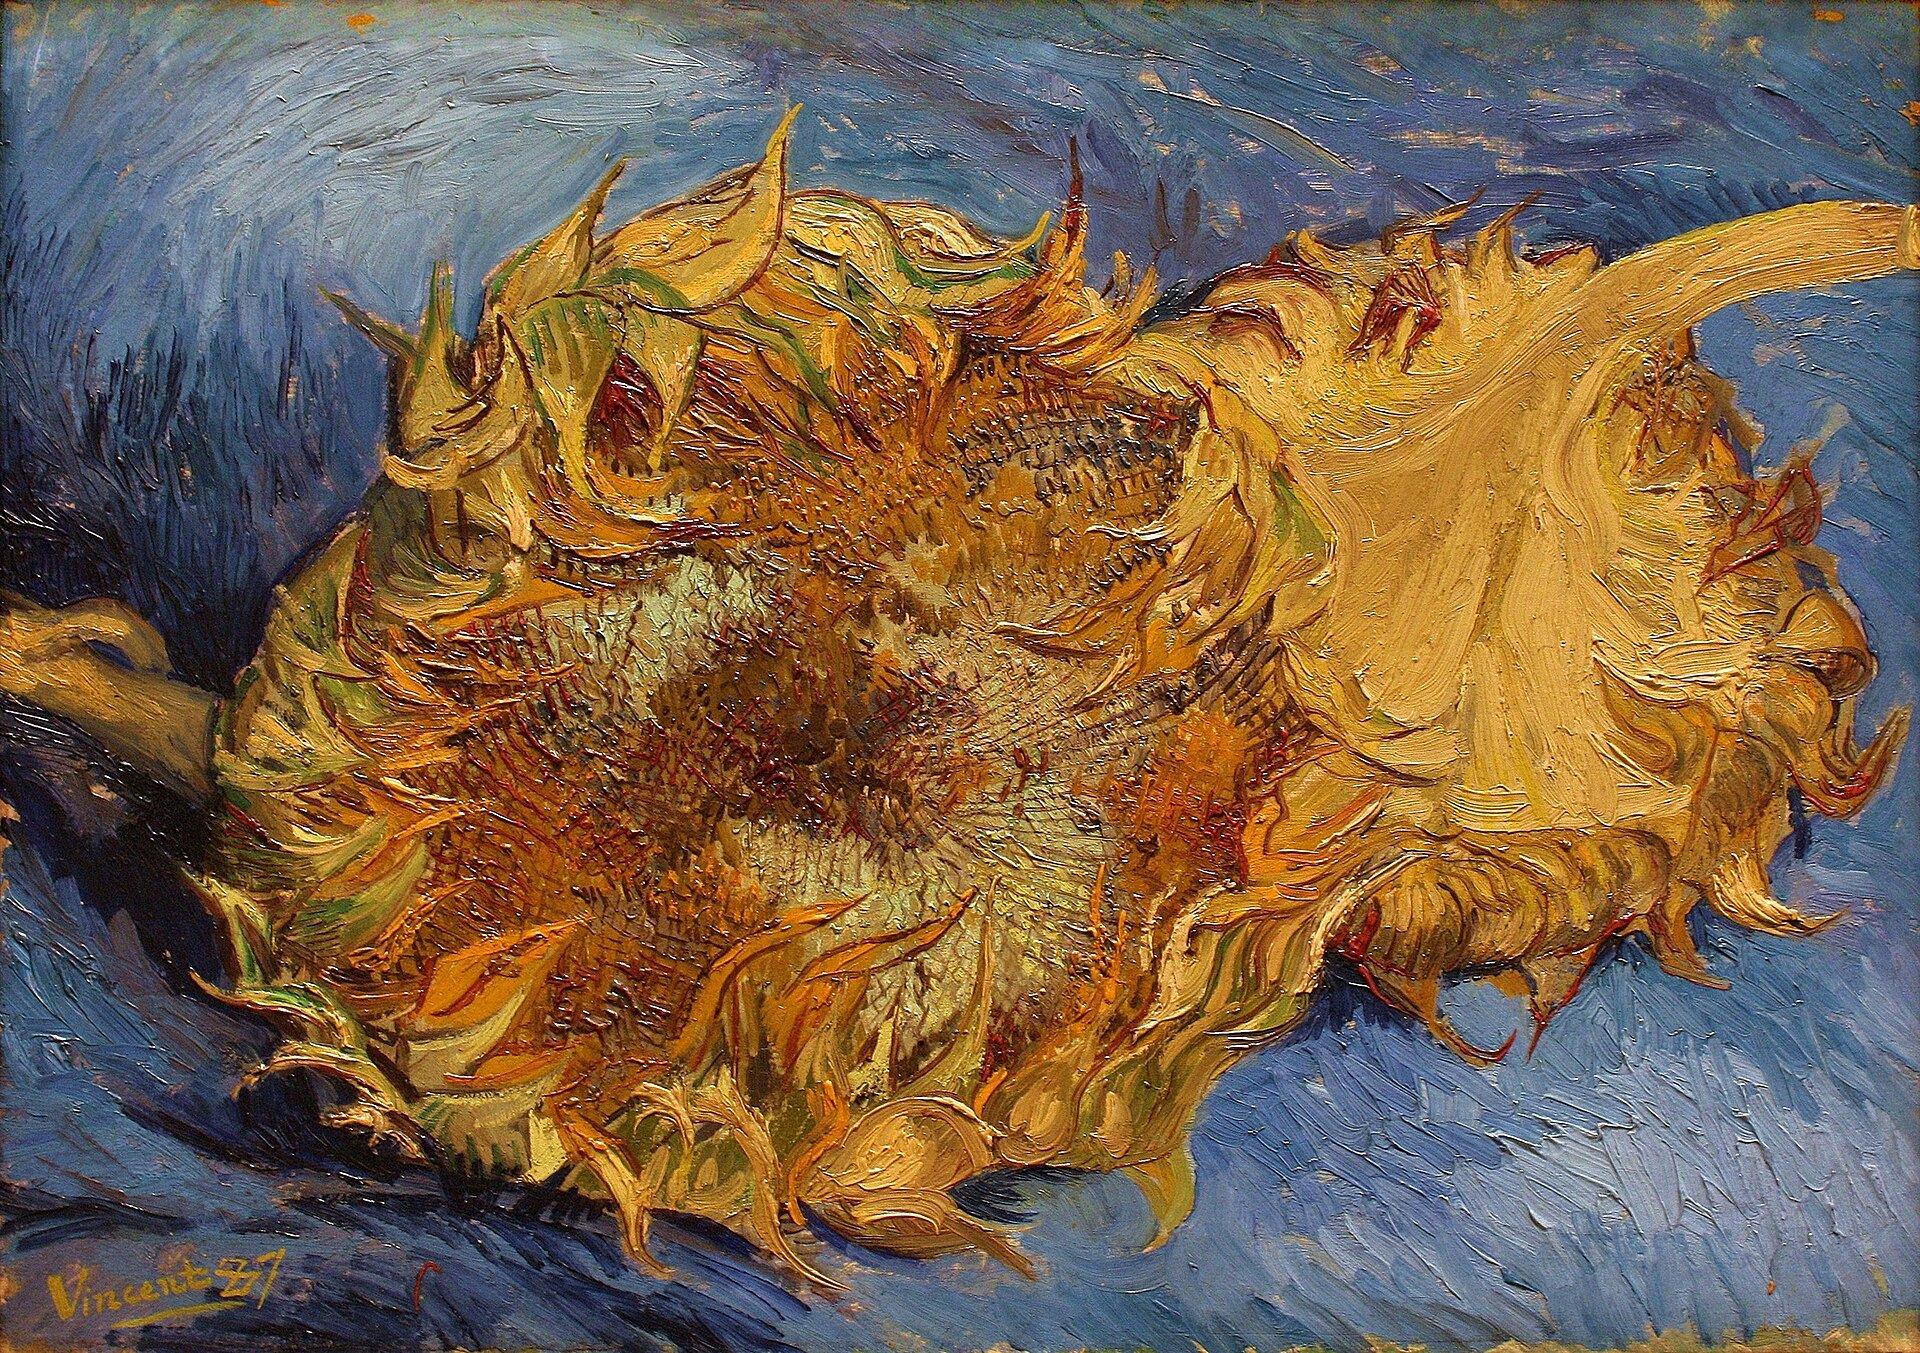

File:Vincent van Gogh - Sunflowers (Metropolitan Museum of Art).jpg source: WIKIMEDIA COMMONS

We can select a few of the items to display and look at here in the codebook

In [ ]:
# Choosing some items to check and print here for review
# Display a few key fields that we are interested in
print("Title:", object_data_search1.get("title"))
print("Artist:", object_data_search1.get("artistDisplayName"))
print("Date:", object_data_search1.get("objectDate"))
print("Medium:", object_data_search1.get("medium"))

It is useful to save this JSON output locally if we were to proceed with the response we got back. In this case we only have one item, but later we will explore others and you may want to keep a record of processes.

In [11]:
metadata_path = Path("Metadata") / f"{first_example_id}_FirstExample_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(object_data_search1, f, indent=2)

## Processing the data for use

There are a number of ways a user might want to work with all the metadata stored in the JSON file. Exploratory look, extraction of key features, and the use here depends on the goal. For this section with just 1 example, we have only metadata for a single object for demonstrative purposes. We will export the key elements of interest into csv tabular format to explore how it lays out, for demonstrative purposes. In later stages where we increase the size of the metadata or images that we collect, we may want to preserve features of the nested JSON structure, combine outputs or convert subsets of data to CSV to clean and sort the data for dedicated use in a project.

Despite this being limited to 1 object, there is enough richness in the metadata to extract and view.
An example of extracting and viewing is shown below


### From JSON to CSV

We have now saved the full metadata for our selected object as a JSON file.

Next, we will reopen this saved file, select the metadata fields most relevant to our research, and convert them into a CSV (Comma-Separated Values) file.

**Why do this?**

- **JSON** keeps the original structured metadata returned by the API, including nested information.
- **CSV** organises selected information into a tabular format, which can be opened in spreadsheet software or used for further analysis.
- Keeping the original JSON allows us to return to the source data if we need additional fields later, without making another API request.


In [ ]:

# Load the correct JSON file
# Use the Object ID selected earlier rather than a fixed ID
json_path = Path("Metadata") / f"{first_example_id}_FirstExample_metadata.json"

with open(json_path, "r", encoding="utf-8") as f:
    search1_object_metadata = json.load(f)


# Extract key metadata fields
search1_first_example_summary = {
    "Object ID": search1_object_metadata.get("objectID"),
    "Title": search1_object_metadata.get("title"),
    "Artist": search1_object_metadata.get("artistDisplayName"),
    "Artist Bio": search1_object_metadata.get("artistDisplayBio"),
    "Date": search1_object_metadata.get("objectDate"),
    "Medium": search1_object_metadata.get("medium"),
    "Dimensions": search1_object_metadata.get("dimensions"),
    "Department": search1_object_metadata.get("department"),
    "Classification": search1_object_metadata.get("classification"),
    "Repository": search1_object_metadata.get("repository"),
    "Credit Line": search1_object_metadata.get("creditLine"),
    "Public Domain": search1_object_metadata.get("isPublicDomain"),
    "Object URL": search1_object_metadata.get("objectURL"),
    "Image URL": search1_object_metadata.get("primaryImageSmall"),
    "Tags": ", ".join([tag["term"] for tag in (search1_object_metadata.get("tags") or [])]),
    "Artist Wikidata": search1_object_metadata.get("artistWikidata_URL"),
    "Object Wikidata": search1_object_metadata.get("objectWikidata_URL"),
}


# Save to CSV using utf-8-sig encoding
csv_path = Path("Converted_Data") / f"{first_example_id}_FirstExample_metadata.csv" ###this is where the file is for the single object.

df = pd.DataFrame([search1_first_example_summary]) ###what we do here is to create a dataframe to export into csv
#tabular format. We save the dataframe as a CSV in this section since it is a minimal example. More on that later.
df.to_csv(csv_path, index=False, encoding="utf-8-sig")

# Display the location of the saved file and preview its contents
print("CSV saved to:", csv_path.resolve())
display(df)


We have now extracted selected fields from the saved JSON and converted them into a tabular format (CSV). This allows us to:

- View and analyse the data in a recognised format.
- Use it in other tools (Excel, R, etc.).
- Select and organise metadata fields relevant to our research.

We use `.get()` to retrieve fields safely, even if they are missing. If a field does not exist, `.get()` returns `None` rather than producing an error. The encoding is set to `utf-8-sig` for compatibility with spreadsheet applications such as Excel.

> **Option — Explore the exported CSV**
>
> Take a look in the `Converted_Data` folder and open the CSV file containing our selected object ID and its related metadata.
>
> The data is stored in an orderly, tabular format, with each metadata field represented as a column. However, some cells contain multiple values or descriptive text. For example, the `Tags` column contains both *Sunflowers* and *Still Life* in a single cell.
>
> This is where **data preprocessing** becomes important if we want to use these records as a structured dataset or corpus for further analysis. Depending on our research question, we might need to separate values, standardise dates, handle missing information or clean text fields.
>
> For now, we are focusing on retrieving, selecting and saving data from an API rather than performing a full analysis.


----------------------------------------SECTION 2---------------------------------------------------------

## From a single item to a small batch & images (if available)

**Search 2**

In [8]:
# These are some of the required imports for the session
import requests              # For sending HTTP requests to the API
import json                  # For working with JSON responses
from pathlib import Path     # For safe file/directory path handling
import pandas as pd          # For working with tabular data
import pprint                # For readable display of nested JSON objects
import time                  # Adding time delay
from collections import Counter
# !pip install requests pandas


Let's try something different and curate a little bit what we do with the object IDs returned from the API by a given keyword, and carefully select a larger number of items to work with.

This section will query the API using the keyword `calligraphy`. We aim to collect metadata (including image information, where available) for a small batch of objects.

Unlike Search 1, where we examined a single object's metadata, we will now work with multiple records and explore the additional considerations involved in retrieving data through repeated API requests.

In [ ]:

search_term_2 = "calligraphy"  # This the term of interest in section 2

# Define the base API URL and query parameters
search_url = "https://collectionapi.metmuseum.org/public/collection/v1.1/search"

params_2 = {
    "q": search_term_2,         # 'q' is the MET API's search keyword parameter
    "hasImages": "true",        # Filter to only return objects with images #this can be removed or modulated
    "offset": 0,                # Start at the first result
    "limit": 50                 # Retrieve 50 object IDs for our batch
}

# Send the GET request
response_2 = requests.get(search_url, params=params_2, timeout=20)
print("Status code:", response_2.status_code) #print the status from the search

# Check the request URL and stop if an HTTP error occurs
print("Request URL:", response_2.url)
response_2.raise_for_status()

# Convert the response into a Python dictionary
search_data_2 = response_2.json() #not saved yet

# Pretty print the full dictionary (which contains 'total' and 'objectIDs')
print("Total:", search_data_2.get("total"))
print("Object IDs returned on this page:", len(search_data_2.get("objectIDs") or []))
pprint.pprint(search_data_2)

> Adjusting query parameters can return different numbers of results and different outputs. For provenance and reproducibility, it is useful to save the JSON response and revisit it if required, particularly when comparing searches or curating a research dataset.  Here, we are saving the **first 50 object IDs** returned by our search, alongside the total number of matching objects. We have not yet retrieved the full metadata for these objects.

For this exercise, we have deliberately limited our search to the first 50 object IDs returned by the API.

This gives us a manageable collection for demonstrating repeated API requests, collecting metadata, filtering records and preparing data for further exploration.

The number 50 is a choice. In a research project, the number of records retrieved would depend on the research question, sampling approach and available resources.

**Note:** These are the first 50 results returned by the API.

In [16]:
metadata_dir = Path("Metadata")

search2_output_path = metadata_dir / "calligraphy_search_data_2.json"

with open(search2_output_path, "w", encoding="utf-8") as f:
    json.dump(search_data_2, f, indent=2)

If we aim to fetch the full metadata for multiple objects returned by our 'calligraphy' search, we need to consider potential issues when sending a larger number of requests to the API server.

In this example, we will retrieve the metadata for the **50 object IDs** returned by our earlier search, rather than all 11,172 matching objects.

Unlike the initial search, which returned a list of object IDs in a single request, we now need to make a separate request for each object's full metadata.

This is a tougher task. Here, we rely on a **loop** to make repeated requests, using each object ID in turn.

A new feature in this section is a **time delay** between requests. This helps us avoid sending requests too quickly and reduces the likelihood of encountering rate limits. However, it does not guarantee that requests will always succeed, particularly when working across different computing environments or network connections.

We will also record the **HTTP status codes** for each request to check which objects were successfully retrieved and which encountered errors.

> **Note:** Pay attention to the status codes printed as the code runs. These allow us to monitor the progress of our requests and identify any unsuccessful responses. We will also save a log of these responses for traceability and reproducibility.

In [ ]:

import time
import json
from pathlib import Path
import requests
###required when you start a new session, or revisit or restart your kernel. In the same session you do not have
#to typically repeat this. Here for convenience.

#Load saved search result from earlier, we saved the object IDs for our search already
search_json_path_2 = Path("Metadata") / "calligraphy_search_data_2.json"
with open(search_json_path_2, "r", encoding="utf-8") as f:
    search_data_2 = json.load(f)

#Get object IDs from search JSON
object_ids_2 = search_data_2.get("objectIDs") or []

# Set an empty list to store metadata dictionaries
all_metadata_2 = []
status_log_lines = [] ##after some test runs, maintaining records for provenance and reproducibility is
#important, keeping a log of the status codes for a large batch is useful

# Loop over object IDs by index position and collect metadata
for idx, obj_id in enumerate(object_ids_2):
    obj_url = f"https://collectionapi.metmuseum.org/public/collection/v1/objects/{obj_id}"

    # Handle network errors so one failed request does not stop the entire loop
    try:
        response = requests.get(obj_url, timeout=20)

        status = response.status_code

        print(f"{idx+1}/{len(object_ids_2)} — {obj_id} — Status code:", response.status_code) ##a way to print out the
        # the IDs and loop position to check the status code. Its more important here since have a larger batch.
        #This makes it easier for us in the session to visualise and is set up in these lines NOT an automatic output
        #from the API.

        # Add line to log
        status_log_lines.append(f"{idx+1}/{len(object_ids_2)} — Object ID: {obj_id} — Status: {status}") ##this is
        #to ensure the log file has sensible formatted info

        if response.status_code != 200:
            continue

        obj_metadata_2 = response.json()
        all_metadata_2.append(obj_metadata_2)

    # Record connection errors or timeouts
    except requests.exceptions.RequestException as e:
        print(f"{idx+1}/{len(object_ids_2)} — {obj_id} — Request error: {e}")
        status_log_lines.append(
            f"{idx+1}/{len(object_ids_2)} — Object ID: {obj_id} — Status: REQUEST_ERROR"
        )

    # Add a delay after every request attempt, including unsuccessful ones
    finally:
        time.sleep(0.2)

# Save full batch metadata as JSON
batch_path = Path("Metadata") / "calligraphy_search2_metadata_batch.json"
with open(batch_path, "w", encoding="utf-8") as f:
    json.dump(all_metadata_2, f, indent=2)

status_log_path = Path("Metadata") / "calligraphy_search2_status_log.txt"
with open(status_log_path, "w", encoding="utf-8") as f:
    f.write("\n".join(status_log_lines))

 ## Quick check - what worked & what did not work

In [ ]:

# Load the saved log file
log_path = Path("Metadata") / "calligraphy_search2_status_log.txt"
with open(log_path, "r", encoding="utf-8") as f:
    lines = f.readlines()

# Extract only the status codes
status_codes = []
object_ids_by_status = {}

for line in lines:
    if "Status:" in line:
        parts = line.strip().split("—")

        # Check that the log entry has the expected structure
        if len(parts) < 3:
            continue

        obj_id = parts[1].strip().replace("Object ID: ", "")
        status = parts[-1].strip().replace("Status: ", "")

        status_codes.append(status)
        object_ids_by_status.setdefault(status, []).append(obj_id)

# Count total per status code
status_summary = Counter(status_codes)

# Print the results
print("Status Code Summary:")
for code, count in status_summary.items():
    print(f"  Status {code}: {count} objects")


# Check how many requests were successful
print(f"\n(200): {status_summary.get('200', 0)}")

# Print failed IDs (including 404s and other errors)
# This is useful because we may have differing outputs on Noteable
# versus when we work locally.

for code, ids in object_ids_by_status.items():
    if code != "200":
        print(f"\nObject IDs with status {code} ({len(ids)}):")
        print(", ".join(ids[:10]) + ("..." if len(ids) > 10 else ""))


In [ ]:
# Load the batch JSON where saved the metadata from each object ID from our 'calligraphy' search.
batch_path = Path("Metadata") / "calligraphy_search2_metadata_batch.json"
with open(batch_path, "r", encoding="utf-8") as f:
    calligraphy_metadata_batch = json.load(f)

print(f"Total: {len(calligraphy_metadata_batch)}")

# Preview a couple of items
# [:3] selects the first three records from our collection
for idx, item in enumerate(calligraphy_metadata_batch[:3], 1):
    print(f"\n{idx}. {item.get('title')} — {item.get('objectDate')} ({item.get('medium')})")

Printing and inspecting using pretty print...choosing key features to extract for a curated dataset

In [ ]:
# Preview the complete metadata for a small selection of records
# [:2] selects the first two records. You can adjust this if needed.

for i, record in enumerate(calligraphy_metadata_batch[:5], 1):  # You can adjust this this if needed
    print(f"\n--- Record {i} ---")
    pprint.pprint(record)

The original JSON contains nested structures (like tags, measurements, constituents).

We can now design and choose a direction for taking elements, into a format to create a structured set of data that we can wrangle, process and analyse if we wish. We will flatten items in many cases.

In [ ]:

# Load the saved metadata batch if not in memory
batch_path = Path("Metadata") / "calligraphy_search2_metadata_batch.json"
with open(batch_path, "r", encoding="utf-8") as f:
    calligraphy_metadata_batch = json.load(f)

# Filter records by department and public domain status
filtered_asian_art = [
    record for record in calligraphy_metadata_batch
    if record.get("department") == "Asian Art" and record.get("isPublicDomain", False)
]

# Check how many records meet our chosen criteria
print(f"Records in original batch: {len(calligraphy_metadata_batch)}")
print(f"Records matching our filters: {len(filtered_asian_art)}")

# Extract relevant fields
extracted_data = []
for record in filtered_asian_art:
    extracted_data.append({
        "Object ID": record.get("objectID"),
        "Title": record.get("title"),
        "Department": record.get("department"),
        "Artist Gender": record.get("artistGender"),
        "Region": record.get("region"),
        "Country": record.get("country"),
        "Object Date": record.get("objectDate"),
        "Medium": record.get("medium"),
        "Object Name": record.get("objectName"),
        "Public Domain": record.get("isPublicDomain"),
        "Primary Image URL": record.get("primaryImageSmall")
    }) ####you can add other features, these are just a selection I picked.

#Save the filtered JSON
subset_json_path = Path("Metadata") / "subset_data_AsianArt.json"
with open(subset_json_path, "w", encoding="utf-8") as f:
    json.dump(extracted_data, f, indent=2)

#Save as CSV for analysis
df_asian_art = pd.DataFrame(extracted_data)
csv_path = Path("Converted_Data") / "subset_data_AsianArt.csv"
df_asian_art.to_csv(csv_path, index=False, encoding="utf-8-sig")

# Save as pickle file too
pkl_path = Path("Metadata") / "subset_data_AsianArt.pkl"
df_asian_art.to_pickle(pkl_path)

# Check a few entries to have a look at what we have
print(f"Total- {len(df_asian_art)}")
print(df_asian_art.head())


This what our dataframe contains and what we selected to export to CSV

In [ ]:
print(df_asian_art.columns)


In [ ]:
# Count how many of the entries have image URLs
with_images = df_asian_art[df_asian_art["Primary Image URL"].str.strip() != ""]
print(f"{len(with_images)} of {len(df_asian_art)}")


All great, we exported a select set of features but some metadata entries have missing values, and curating the filter process you require for a unified dataset requires choosing a variety of the features from the JSON to capture more detail for your chosen subset.

In [ ]:
# Image folder
image_dir = Path("Image_Data")

status_log2 = []

# Loop over the dataframe and download images
for _, row in df_asian_art.iterrows():
    image_url = row.get("Primary Image URL")
    object_id = row.get("Object ID")####we already know all 64 object IDs had a working image url.
    #but looping over helps to identify any issues with larger sets.

    if image_url and pd.notna(image_url) and str(image_url).strip():
        ext = image_url.split('.')[-1].split("?")[0]
        img_path = image_dir / f"{object_id}.{ext}"

        try:
            response = requests.get(image_url, timeout=10)
            status_log2.append(f"{object_id} — {response.status_code}")
            if response.status_code == 200:
                with open(img_path, "wb") as f:
                    f.write(response.content)
            else:
                print(f"[{object_id}] Skipped status {response.status_code}")
        except Exception as e:
            print(f"[{object_id}] An error: {e}")

# Print status log after all requests complete
print("\n-Status Log")
for line in status_log2:
    print(line)
    
status_log_path = Path("Metadata") / "search2image_status_log.txt"
with open(status_log_path, "w", encoding="utf-8") as f:
    f.write("\n".join(status_log2))


We used the dataframe we had made of our subset data Asian Art, it had full rows for the primary images for every object ID and we have been able to extract them out into the Image_Data folder.

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

#Relevant text fields
text_fields = df_asian_art[["Title", "Object Name", "Medium", "Object Date"]].fillna("")
combined_text = " ".join(df_asian_art[col].astype(str).str.cat(sep=" ") for col in text_fields.columns)

#Generate and display word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(combined_text)
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud: Asian Art Subset")
plt.show()


----------------------------------------SECTION 3 -------------------------------------------------

# Multi-layered queries


## Combining Search Terms and Query Parameters

We may wish to layer queries in an API request, combining different topics, keywords or filters to investigate patterns and identify records relevant to a particular research question.

We can explore the available endpoints and documentation to assess what kinds of objects we would like to collect, or experiment with combinations of keywords and query parameters.

In the query parameters, we can also use Boolean values (`true` or `false`), as we did earlier with `hasImages=true`, and introduce further filters where these are supported by the API.

**Important:** A Boolean parameter such as `hasImages=true` is not the same as using Boolean search operators (`AND`, `OR`, `NOT`) to combine keywords.

Different APIs support different search methods, parameters and filtering options. No two APIs necessarily work in exactly the same way, so it is important to consult their documentation.

In some ways, this is similar to formulating systematic literature searches, where researchers combine search terms and filters to refine the information retrieved. However, the available search logic depends on the particular service.

### Exploring Multiple Search Terms

It is not explicitly clear from the Met API documentation how multiple keywords within a single `q` parameter are interpreted.

Below, we will run a demonstrative example combining several terms relating to Japanese art:

`Japan, Samurai, Edo, Ink`

We will examine the results to understand how the API responds to this query.

**Consider:** Entering several terms does not necessarily mean the API will search for records containing all of them. We need to investigate the returned results before drawing conclusions about how the search works.

We will also continue practising the retrieval of object IDs, collecting metadata and preparing a dataset for further exploration.


**Search 3**

In [ ]:
# These are some of the required imports for the session
import requests              # For sending HTTP requests to the API
import json                  # For working with JSON responses
from pathlib import Path     # For file/directory path handling
import pandas as pd          # For working with tabular data
import pprint                # For readable display of nested JSON objects and other printed items
import time                  # Adding time delay when we get data from the API
from collections import Counter #counting things
### we add this block here in case there is a kernel refresh as we go along in the session

In [ ]:
# the base URL for the Met Museum API --- and the version is noted
base_url = "https://collectionapi.metmuseum.org/public/collection/v1.1"

# Define the multi-term search query
search_3_query = "Japan, Samurai, Edo, Ink"

# Perform the search request --- above we defined the base and the search so the below line can incorporate 
#them in a succinct line.
search_3_response = requests.get(f"{base_url}/search", params={"q": search_3_query})

# Check response and parse object IDs
if search_3_response.status_code == 200:
    search_data_3 = search_3_response.json()
    object_ids_3 = search_data_3.get("objectIDs", []) or []
    print(f"Total results: {search_data_3.get('total', 0)}")
    print(f"First 10: {object_ids_3[:10]}")
else:
    print(f"potential errors: {search_3_response.status_code}")


In [34]:
#Save Search 3 Object IDs JSON ---
metadata_dir = Path("Metadata")
search3_ids_path = metadata_dir / "search3_object_ids.json"
with open(search3_ids_path, "w", encoding="utf-8") as f:
    json.dump({"objectIDs": object_ids_3}, f, indent=2)

We take 50 to work with

In [ ]:
# directory
metadata_dir = Path("Metadata")

#Retrieve metadata from the Met API ---
search3_metadata = []
status_log3 = []

for idx, obj_id in enumerate(object_ids_3[:50], 1):
    obj_url = f"https://collectionapi.metmuseum.org/public/collection/v1/objects/{obj_id}"
    try:
        response = requests.get(obj_url, timeout=10)
        status = response.status_code
        status_log.append(f"{idx}/{len(object_ids_3)} — ID: {obj_id} — Status: {status}")
        ### Added some readability elements for the printout for us to review
        if status == 200:
            search3_metadata.append(response.json())
        else:
            continue
    except Exception as e:
        status_log.append(f"{idx}/{len(object_ids_3)} — ID: {obj_id} — Error: {e}")
    time.sleep(0.2)

# Print status log after all requests are complete
print("\n--- Status Log ---")
for line in status_log3:
    print(line)
    
status_log_path = Path("Metadata") / "search3_status_log.txt"
with open(status_log_path, "w", encoding="utf-8") as f:
    f.write("\n".join(status_log3))

### we simply take the first 50, there is no inherent order in the object id list, you can also specify
#ID if that is preferred. So this is simply the first 50 items.


In [36]:
# Save metadata as JSON ---
search3_metadata_path = metadata_dir / "search3_metadata_batch.json"
with open(search3_metadata_path, "w", encoding="utf-8") as f:
    json.dump(search3_metadata, f, indent=2)

In [ ]:
# Load the saved metadata JSON
with open(search3_metadata_path, "r", encoding="utf-8") as f:
    loaded_metadata = json.load(f)

# Pretty print first 3 entries - pretty print is used to print things 'nicely' , it is a preference
for i, item in enumerate(loaded_metadata[:3], 1):
    print(f"\n--- Record {i} ---")
    print(json.dumps(item, indent=2))

Let's add a few extra fields to expand on this output

Here, in an effort to create a richer set, we can add more of the available fields to populate our outputs

In [ ]:
metadata_dir = Path("Metadata")
converted_dir = Path("Converted_Data")

# Load the saved Search 3 metadata
search3_metadata_path = metadata_dir / "search3_metadata_batch.json"
with open(search3_metadata_path, "r", encoding="utf-8") as f:
    search3_metadata = json.load(f)

# Extract extended fields from each record
records = []
for item in search3_metadata:
    records.append({
        "Object ID": item.get("objectID"),
        "Title": item.get("title"),
        "Artist Name": item.get("artistDisplayName"),
        "Artist Gender": item.get("artistGender"),
        "Culture": item.get("culture"),
        "Country": item.get("country"),
        "Region": item.get("region"),
        "Subregion": item.get("subregion"),
        "Period": item.get("period"),
        "Dynasty": item.get("dynasty"),
        "Object Date": item.get("objectDate"),
        "Object Begin Date": item.get("objectBeginDate"),
        "Object End Date": item.get("objectEndDate"),
        "Medium": item.get("medium"),
        "Dimensions": item.get("dimensions"),
        "Object Name": item.get("objectName"),
        "Classification": item.get("classification"),
        "Department": item.get("department"),
        "Public Domain": item.get("isPublicDomain"),
        "Primary Image URL": item.get("primaryImageSmall"),
        "Object URL": item.get("objectURL")
    })

# Create DataFrame which allows us to work here easily and draw on data features.
df_search3 = pd.DataFrame(records)

# Save as CSV in our preferred directory
csv_path = converted_dir / "subset_data_search3.csv"
df_search3.to_csv(csv_path, index=False, encoding="utf-8-sig")

# Save as Pickle file (just a failsafe option)
pkl_path = metadata_dir / "subset_data_search3.pkl"
df_search3.to_pickle(pkl_path)

# Preview to take a look
print(f"{len(df_search3)} records from Search 3.")
print(df_search3.head())

We have something like this:

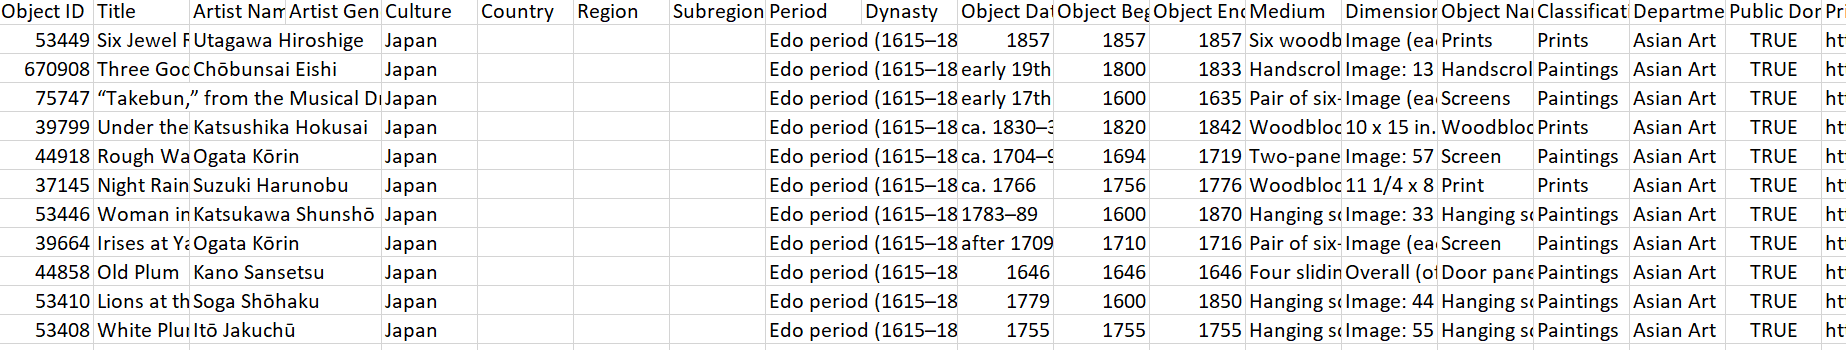

The multiple terms for search have worked effectively, allowing us to combine multiple items in the query to request object IDs, then associated metadata (after we reduced the size) - 5000 would have been far too much and we would have to set an iterative code block to add delays, fallbacks and other features to avoid blocks/crashes, and errors.

Accounting for delays, and looping back over available IDs even where status codes faltered is possible with logging and creating dataframes or lists to re-run through those if it is essential to capture as much as possible.

#### Taking a look at the data

We can plot a few things...

In [ ]:
import matplotlib.pyplot as plt

# Count top 10 mediums from search 3
df_search3['Medium'].value_counts().nlargest(10).plot(kind='barh')
plt.title("Top 10 Mediums in Search 3")
plt.xlabel("Number of Artworks")
plt.ylabel("Medium")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [ ]:
# Histogram of object begin dates (does not include pre-1000 but a quick snapshot) - numerous options available
# depending on what you intend to investigate with the data.
df_search3['Object Begin Date'].hist(bins=20)
plt.title("Distribution of Object Begin Dates")
plt.xlabel("Year")
plt.ylabel("Number of Artworks")
plt.tight_layout()
plt.show()


In reality, a larger dataset would require cleaning and preprocessing to tangibly work with it

We can take a look at the overall shape, examine missing items and so forth...We have the data saved as a dataframe here so we can call and examine items

In [ ]:
# Basic overview to assess the data overall, its shape, length and dimensions (what do we have)
print("DataFrame Shape:", df_search3.shape)
print("\nColumn Names:", df_search3.columns.tolist())

# Count missing values per column - this handy if you want to work with only complete data or are interested
# in what is missing from a historical perspective for instance..
print("\nMissing Values Per Column:")
print(df_search3.isna().sum())

# Count unique values per column
print("\nUnique Values Per Column:")
print(df_search3.nunique())

# Quick value counts for select columns
print("\nTop Departments:")
print(df_search3['Department'].value_counts())
#Classifications was listed in the documentation for the Met, it is how the team there have grouped and classified certain objects.
print("\nTop Classifications:")
print(df_search3['Classification'].value_counts().head(10))


In our previous exercises, we used the Metropolitan Museum of Art API to search for objects, retrieve metadata, filter records and explore the results.

Researchers may also wish to construct more sophisticated queries, combining search terms and conditions to retrieve information relevant to a particular research question.

Some APIs support **Boolean search operators**, similar to those used in systematic literature searches and academic databases.

### Understanding Boolean Operators

Boolean operators allow us to combine or exclude search conditions.

| Operator | Purpose | Example |
|---|---|---|
| **AND** | Returns records matching both conditions. | `painting AND landscape` |
| **OR** | Returns records matching at least one condition. | `painting OR sculpture` |
| **NOT** | Excludes records matching a condition. | `painting NOT portrait` |

These operators can help researchers refine searches, compare collections or investigate relationships between different concepts.

However, **not all APIs support Boolean operators directly in their search parameters**.

### Boolean Searching Across Different APIs

Different APIs provide different ways to combine search conditions.

| API | Search capabilities | Research relevance |
|---|---|---|
| **Metropolitan Museum of Art** | Supports keyword searches and documented filters, but does not document general Boolean keyword operators. | Searching and refining cultural heritage records using metadata and parameters. |
| **Europeana** | Supports `AND`, `OR`, `NOT`, parentheses and field-specific searches. | Combining concepts across European museum, library and archive collections. |
| **Art Institute of Chicago** | Supports Elasticsearch Boolean queries using `must`, `should` and `must_not`. | Constructing complex searches across different artwork metadata fields. |

### Examples of More Complex Queries

**Europeana**

Europeana allows Boolean operators to be included in the query itself.

For example:

`painting AND landscape`

This searches for records matching both terms.

A field-specific query might be:

`where:(Paris OR London)`

This searches for records associated with either location.

Europeana requires an API key for accessing its Search API.

**Art Institute of Chicago**

The Art Institute of Chicago uses Elasticsearch to support more complex search structures.

Its Boolean query system includes:

- `must` — conditions that must match.
- `should` — alternative conditions, which can support OR-style searches.
- `must_not` — conditions used to exclude records.

These conditions can be applied to specific metadata fields, such as artwork titles, artists or materials.

For example, a researcher could construct a query examining artworks whose titles mention Chicago and whose artist metadata matches Louis Sullivan, or compare results using alternative and exclusion conditions.

### Research Considerations

When designing advanced API searches, consider:

- **Documentation:** Does the API support Boolean operators, and what syntax does it require?
- **Metadata:** Which fields are searchable, and how are they indexed?
- **Search logic:** How are multiple terms, phrases and conditions interpreted?
- **Coverage:** Could relevant records be excluded because of incomplete metadata?
- **Reproducibility:** Have the query parameters and collection methods been documented?

It is also important to distinguish between **Boolean operators used within an API request** and **filtering data locally after retrieval**. Both can be useful, but they operate at different stages of the research workflow.

**Key takeaway:** Advanced search capabilities vary between APIs. Researchers should examine the available parameters, supported operators and documentation before constructing complex queries.

That is a run through of a few things we have completed in this code book:

High level:
- Making an API request
- Collecting metadata (text and image)
- Assessing and recording workflow
- Status code tracking
- Retrieving larger sets of metadata (text)
- Carrying out a multi-term query

Specifics:
- Using the search endpoint of an API url to find items
- Adapting the URL endpoint to then retrieve metadata
- Working with the JSON file to subset and extract items
- Converting subsets of data to csv for local working 
- Extracting images from available URLs which have open rights for access
- Understanding documentation parameters for requests to API
- Working with extracted and exported data briefly
- Examining varying possibilities with a REST - web API
- Understanding status codes and comparing home vs institution IP.



